# 0a_01 Outcomes, Events and the Sample Space: The Language of Probability

**Learning objectives**
- Describe an experiment by its **sample space** (all possible outcomes) and its **events** (sets of outcomes).
- Combine events with **union, intersection, complement and difference**, and draw them as Venn diagrams and grids.
- State the three **axioms of probability** and compute $P(A)=|A|/|S|$ when outcomes are equally likely.
- Check a probability by **listing outcomes in code** and by **simulation**.

**Prerequisites:** none. School arithmetic and fractions are enough. This is the first lesson of the book.

## 1. Setup

All imports in one cell; the generator is seeded so every run gives the same numbers.

In [1]:
import sys
sys.path.append("../..")  # repo root, so common.style can be imported
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.graph_objects as go
from scipy import stats
from common.style import apply_style, MAIN, SIM, HIGHLIGHT, NEUTRAL, COLORS

apply_style()
rng = np.random.default_rng(42)  # fixed seed so every run gives the same numbers

import itertools
from matplotlib.patches import Circle, Rectangle

## 2. Prerequisite recap

Nothing is assumed, but three everyday ideas help:
- A **set** is a collection of distinct things, written with braces, for example $\{1,2,3\}$. Order does not matter.
- A **fraction** $\frac ab$ compares a part $a$ to a whole $b$; a **probability** is a fraction between 0 and 1.
- A **percentage** is a fraction times 100: $\frac14=25\,\%$.

## 3. Intuition and story

Before computing any probability we must say **what could happen**. Roll a die: the possible results are 1, 2, 3, 4, 5, 6. Draw a card: 52 possibilities. Time a delivery: any positive number of minutes. Probability is a way of attaching a number between 0 and 1 to questions such as "what is the chance the die shows an even number?" or "what is the chance a customer buys *and* returns the item?".

Each such question is about a **group of outcomes**: "even" means $\{2,4,6\}$. That group is an **event**. So probability needs only three ingredients:

1. the **sample space** $S$: the set of all possible outcomes,
2. **events**: subsets of $S$ (the groups we ask about),
3. a rule that gives each event a number $P(\text{event})$.

Everything in this book (Binomial, Normal, Poisson and the rest) is a clever way to write down that third ingredient for a particular kind of experiment.

## 4. Formal definitions

| Term | Meaning | Example (one die) |
|---|---|---|
| **Experiment** | a process with an uncertain result | roll a die once |
| **Outcome** | one possible result | 4 |
| **Sample space** $S$ | the set of all outcomes | $\{1,2,3,4,5,6\}$ |
| **Event** | a subset of $S$ | $E=\{2,4,6\}$ ("even") |
| **Elementary event** | an event with one outcome | $\{4\}$ |
| **Complement** $A^c$ | outcomes *not* in $A$ | $E^c=\{1,3,5\}$ |
| **Union** $A\cup B$ | in $A$ **or** $B$ (or both) | $\{2,4,6\}\cup\{1,2\}=\{1,2,4,6\}$ |
| **Intersection** $A\cap B$ | in $A$ **and** $B$ | $\{2,4,6\}\cap\{1,2\}=\{2\}$ |
| **Difference** $A\setminus B$ | in $A$ but not in $B$ | $\{2,4,6\}\setminus\{1,2\}=\{4,6\}$ |
| **Mutually exclusive** | $A\cap B=\varnothing$ (cannot both happen) | $\{1,2\}$ and $\{5,6\}$ |
| **Exhaustive** | $A\cup B\cup\cdots=S$ (one of them must happen) | $E$ and $E^c$ |

**Axioms of probability** (Kolmogorov). A probability $P$ assigns a number to every event so that
1. $P(A)\ge0$ for every event $A$,
2. $P(S)=1$ (something must happen),
3. if $A$ and $B$ are mutually exclusive, $P(A\cup B)=P(A)+P(B)$ (and likewise for any number of mutually exclusive events).

**Equally likely outcomes.** If $S$ has $N$ outcomes that are all equally likely, then $P(A)=\dfrac{|A|}{N}$, where $|A|$ is the number of outcomes in $A$.

## 5. Derivations

Every rule below follows from the three axioms.

### 5.1 The complement rule
$A$ and $A^c$ are mutually exclusive and together make $S$, so by axioms 2 and 3: $P(A)+P(A^c)=P(S)=1$, hence $$P(A^c)=1-P(A).$$ **In plain words.** The chance something does *not* happen is 1 minus the chance it does. This is often the shortcut for "at least one" questions.

### 5.2 The empty event and bounds
$S$ and $\varnothing$ are complements, so $P(\varnothing)=1-P(S)=0$. Since probabilities are non-negative and $P(A)+P(A^c)=1$, every $P(A)\le1$. **In plain words.** An impossible event has probability 0, a certain event 1, and nothing is larger than certain.

### 5.3 The addition rule for any two events
Split $A\cup B$ into three mutually exclusive pieces: $A\setminus B$, $A\cap B$ and $B\setminus A$. Then $P(A\cup B)=P(A\setminus B)+P(A\cap B)+P(B\setminus A)$. Also $P(A)=P(A\setminus B)+P(A\cap B)$ and $P(B)=P(B\setminus A)+P(A\cap B)$. Adding the last two counts the overlap twice, so $$P(A\cup B)=P(A)+P(B)-P(A\cap B).$$ **In plain words.** Adding $P(A)$ and $P(B)$ counts the outcomes in both events twice; subtract them once.

### 5.4 De Morgan's laws
$(A\cup B)^c=A^c\cap B^c$ ("not (A or B)" means "not A and not B") and $(A\cap B)^c=A^c\cup B^c$. **In plain words.** To fail an "or", you must fail both parts; to fail an "and", you only need to fail one part.

### 5.5 Equally likely outcomes
If each of the $N$ outcomes has the same probability $q$, axioms 2 and 3 give $Nq=1$, so $q=1/N$, and an event with $|A|$ outcomes has $P(A)=|A|/N$.

## 6. Properties and relationships

- **Mutually exclusive is not independent.** If $A$ happens, a mutually exclusive $B$ *cannot* happen, so they are strongly linked. Independence is a different idea (0a_04).
- **Subsets:** if $A\subseteq B$ then $P(A)\le P(B)$ ("rolling a 6" is less likely than "rolling an even number").
- **Partition:** events that are mutually exclusive and exhaustive split $S$ into pieces whose probabilities add to 1 (used for total probability in 0a_05).
- **Link to later lessons:** a random variable (0a_06 and Module 00) is just a rule that attaches a number to each outcome; the events "X = 3" or "X > 5" are subsets of $S$.

## 7. 2D visuals

### 7.1 The sample space of two dice as a grid
Roll two dice, one red and one blue. Each of the $6\times6=36$ cells is one outcome (red, blue), all equally likely. The events $A$: "sum is 7" and $B$: "at least one six" are highlighted: the overlap cells are in both.

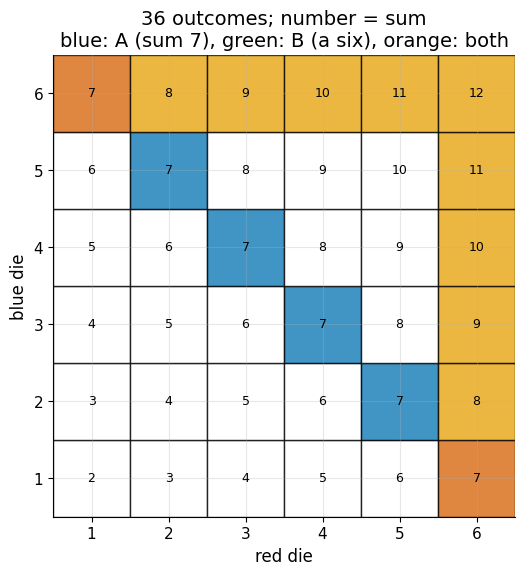

|S| = 36, |A| = 6, |B| = 11, |A and B| = 2, |A or B| = 15


In [2]:
S = list(itertools.product(range(1, 7), range(1, 7)))          # all 36 outcomes (red, blue)
A = {o for o in S if o[0] + o[1] == 7}                            # sum is 7
B = {o for o in S if 6 in o}                                      # at least one six
fig, ax = plt.subplots(figsize=(6.4, 6.0))
for r, b in S:
    in_a, in_b = (r, b) in A, (r, b) in B
    color = HIGHLIGHT if (in_a and in_b) else MAIN if in_a else SIM if in_b else "white"
    ax.add_patch(Rectangle((r - 0.5, b - 0.5), 1, 1, facecolor=color, edgecolor="black", alpha=0.75))
    ax.text(r, b, f"{r + b}", ha="center", va="center", fontsize=9)
ax.set_xlim(0.5, 6.5); ax.set_ylim(0.5, 6.5); ax.set_xlabel("red die"); ax.set_ylabel("blue die"); ax.set_aspect("equal")
ax.set_title("36 outcomes; number = sum\nblue: A (sum 7), green: B (a six), orange: both")
plt.show()
print(f"|S| = {len(S)}, |A| = {len(A)}, |B| = {len(B)}, |A and B| = {len(A & B)}, |A or B| = {len(A | B)}")

### 7.2 Venn diagram of two events
The two circles show $A$ and $B$ inside the sample space rectangle. The overlap is $A\cap B$; the outside of both circles is $(A\cup B)^c$. The numbers are counts of the 36 outcomes.

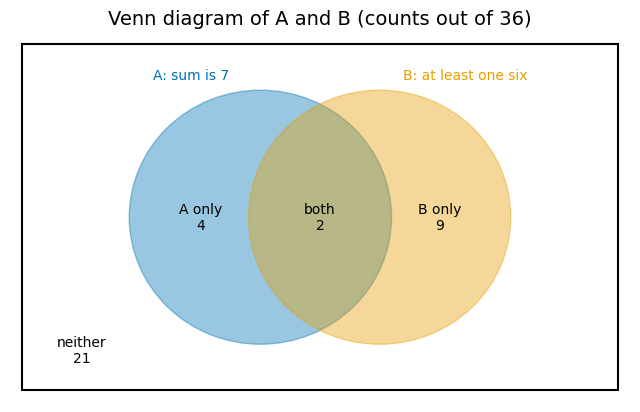

In [3]:
fig, ax = plt.subplots(figsize=(8, 4.8))
ax.add_patch(Rectangle((0, 0), 10, 6, fill=False, edgecolor="black", linewidth=1.5))
ax.add_patch(Circle((4, 3), 2.2, facecolor=MAIN, alpha=0.4, edgecolor=MAIN))
ax.add_patch(Circle((6, 3), 2.2, facecolor=SIM, alpha=0.4, edgecolor=SIM))
ax.text(3.0, 3, f"A only\n{len(A - B)}", ha="center", va="center"); ax.text(7.0, 3, f"B only\n{len(B - A)}", ha="center", va="center")
ax.text(5.0, 3, f"both\n{len(A & B)}", ha="center", va="center"); ax.text(1.0, 0.7, f"neither\n{len(S) - len(A | B)}", ha="center", va="center")
ax.text(2.2, 5.4, "A: sum is 7", color=MAIN); ax.text(6.4, 5.4, "B: at least one six", color=SIM)
ax.set_xlim(-0.2, 10.2); ax.set_ylim(-0.2, 6.2); ax.axis("off"); ax.set_title("Venn diagram of A and B (counts out of 36)")
plt.show()

### 7.3 The probabilities of all sums
Counting the cells of the grid by sum gives the probability of each sum. The shape (a triangle peaking at 7) is a first example of a *distribution*: how probability is spread over the possible values.

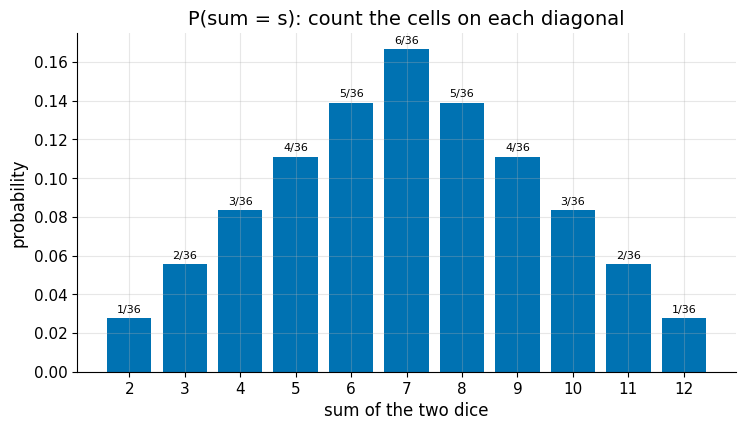

In [4]:
sums = pd.Series([r + b for r, b in S]).value_counts().sort_index()
fig, ax = plt.subplots(figsize=(8.5, 4.4))
ax.bar(sums.index, sums.values / 36, color=MAIN)
for s_, c_ in sums.items():
    ax.text(s_, c_ / 36 + 0.003, f"{c_}/36", ha="center", fontsize=8)
ax.set_xlabel("sum of the two dice"); ax.set_ylabel("probability"); ax.set_title("P(sum = s): count the cells on each diagonal"); ax.set_xticks(range(2, 13))
plt.show()
assert sums.sum() == 36 and sums[7] == 6

## 8. 3D visuals

### 8.1 Static: the 36 outcomes as 3D bars
Height 1 means "this outcome is in the event". Left to right: the sample space with event $A$ (sum is 7) raised, the union $A\cup B$ raised. Each raised bar is one outcome counted by the rule $P=|\text{event}|/36$.

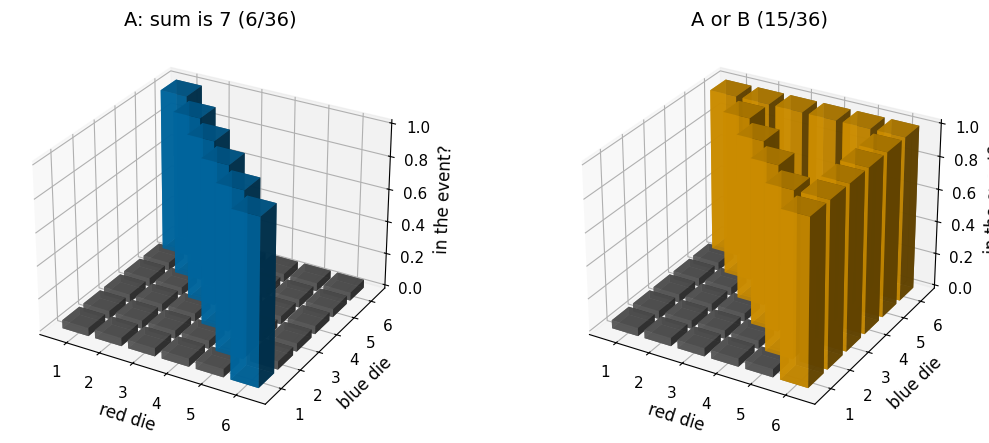

In [5]:
fig = plt.figure(figsize=(13, 5.2))
for k, (ev, title, col) in enumerate([(A, f"A: sum is 7 ({len(A)}/36)", MAIN), (A | B, f"A or B ({len(A | B)}/36)", SIM)]):
    ax = fig.add_subplot(1, 2, k + 1, projection="3d")
    xs, ys = np.meshgrid(range(1, 7), range(1, 7), indexing="ij")
    heights = np.array([[1.0 if (x, y) in ev else 0.05 for y in range(1, 7)] for x in range(1, 7)])
    colors = np.array([[col if (x, y) in ev else NEUTRAL for y in range(1, 7)] for x in range(1, 7)], dtype=object)
    ax.bar3d(xs.ravel() - 0.4, ys.ravel() - 0.4, 0, 0.8, 0.8, heights.ravel(), color=colors.ravel(), alpha=0.85)
    ax.set_title(title); ax.set_xlabel("red die"); ax.set_ylabel("blue die"); ax.set_zlabel("in the event?"); ax.view_init(elev=28, azim=-60)
plt.show()

### 8.2 Interactive Plotly version
Rotate the bars and hover to see which outcomes belong to $A\cup B$ (height 1).

In [6]:
xs = [r for r, b in S]; ys = [b for r, b in S]
zs = [1 if (r, b) in (A | B) else 0.05 for r, b in S]
fig = go.Figure(go.Scatter3d(x=xs, y=ys, z=zs, mode="markers", marker=dict(size=6, color=zs, colorscale="Viridis"),
                             text=[f"({r},{b}) sum {r + b}" for r, b in S], hoverinfo="text"))
fig.update_layout(title="A or B on the 6 x 6 grid", width=700, height=520, scene=dict(xaxis_title="red die", yaxis_title="blue die", zaxis_title="in A or B (1 = yes)"))
fig.show()

## 9. Simulation vs theory

The **long-run frequency** of an event approaches its probability. Roll the pair of dice many times and watch the running frequency of $A$ (sum is 7), $B$ (a six) and $A\cap B$ settle at $6/36$, $11/36$ and $2/36$.

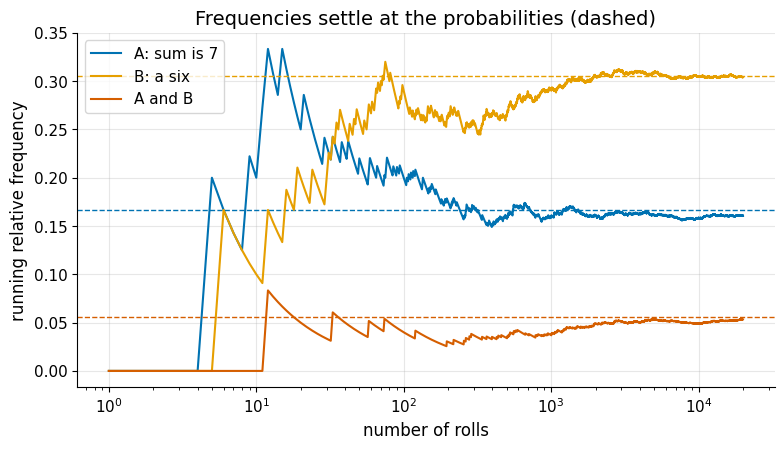

after 20000 rolls: A 0.1606 (6/36 = 0.1667) | B 0.3040 (0.3056) | A and B 0.0532 (0.0556) | A or B 0.4114 (0.4167)


In [7]:
n_rolls = 20_000
red, blue = rng.integers(1, 7, n_rolls), rng.integers(1, 7, n_rolls)
is_a, is_b = (red + blue == 7), ((red == 6) | (blue == 6))
steps = np.arange(1, n_rolls + 1)
fig, ax = plt.subplots(figsize=(9, 4.6))
for flag, label, target, c in [(is_a, "A: sum is 7", 6 / 36, MAIN), (is_b, "B: a six", 11 / 36, SIM), (is_a & is_b, "A and B", 2 / 36, HIGHLIGHT)]:
    ax.plot(steps, np.cumsum(flag) / steps, color=c, label=label)
    ax.axhline(target, color=c, linestyle="--", linewidth=1)
ax.set_xscale("log"); ax.set_xlabel("number of rolls"); ax.set_ylabel("running relative frequency"); ax.set_title("Frequencies settle at the probabilities (dashed)"); ax.legend()
plt.show()
print(f"after {n_rolls} rolls: A {is_a.mean():.4f} (6/36 = {6 / 36:.4f}) | B {is_b.mean():.4f} ({11 / 36:.4f}) | A and B {(is_a & is_b).mean():.4f} ({2 / 36:.4f}) | A or B {(is_a | is_b).mean():.4f} ({15 / 36:.4f})")
assert abs(is_a.mean() - 6 / 36) < 0.01 and abs((is_a | is_b).mean() - 15 / 36) < 0.012

## 10. `scipy.stats` and NumPy cheat sheet for this lesson

At this stage we need only a few tools: Python sets and `itertools.product` to list outcomes, `numpy` to simulate, and `scipy.stats.randint` for a fair die.

In [8]:
die = stats.randint(1, 7)                               # a fair die: values 1..6
print("P(die = 4) =", round(die.pmf(4), 4), "| P(die <= 2) =", round(die.cdf(2), 4), "| 5 rolls:", die.rvs(5, random_state=1))
red_set, blue_set = {1, 2, 3}, {3, 4}
print("union:", red_set | blue_set, "| intersection:", red_set & blue_set, "| difference:", red_set - blue_set)
print("all outcomes of two coins:", list(itertools.product("HT", repeat=2)))
print("sample from a list: rng.choice(['red', 'green'], size=5) ->", rng.choice(["red", "green"], size=5))
print("fraction of an event in a simulation: np.mean(rolls >= 5) ->", np.mean(rng.integers(1, 7, 100_000) >= 5).round(3), "(theory 2/6 = 0.333)")

P(die = 4) = 0.1667 | P(die <= 2) = 0.3333 | 5 rolls: [6 4 5 1 2]
union: {1, 2, 3, 4} | intersection: {3} | difference: {1, 2}
all outcomes of two coins: [('H', 'H'), ('H', 'T'), ('T', 'H'), ('T', 'T')]
sample from a list: rng.choice(['red', 'green'], size=5) -> ['green' 'green' 'red' 'green' 'green']
fraction of an event in a simulation: np.mean(rolls >= 5) -> 0.336 (theory 2/6 = 0.333)


## 11. Real-world worked examples

---
### Example 1 (main): a board game with two dice

**Scenario.** In a board game a player rolls a red and a blue die. A move is **safe** if the sum is 7 (event $A$), the player gets a **bonus** if at least one die shows a six (event $B$), and **doubles** (both dice equal, event $D$) give an extra turn.

**Questions**
1. List the sample space. How many outcomes are there?
2. Find $P(A)$, $P(B)$, $P(A\cap B)$ and $P(A\cup B)$.
3. What is the probability of **no extra turn** (not doubles)?
4. What is the probability of **neither a safe move nor a bonus**?

### 11.1 By hand
**Q1.** Each die has 6 faces, so there are $6\times6=36$ equally likely outcomes $(r,b)$.

**Q2.** $A=\{(1,6),(2,5),(3,4),(4,3),(5,2),(6,1)\}$ so $P(A)=\frac6{36}=\frac16$. For $B$ count the outcomes with no six ($5\times5=25$) and subtract: $|B|=36-25=11$, $P(B)=\frac{11}{36}$. $A\cap B=\{(1,6),(6,1)\}$ so $P(A\cap B)=\frac2{36}$. By the addition rule $P(A\cup B)=\frac6{36}+\frac{11}{36}-\frac2{36}=\frac{15}{36}=\frac5{12}$.

**Q3.** Doubles $D=\{(1,1),\dots,(6,6)\}$, $P(D)=\frac6{36}$, so $P(D^c)=1-\frac16=\frac56$.

**Q4.** "Neither" is $(A\cup B)^c$: $1-\frac{15}{36}=\frac{21}{36}=\frac7{12}$ (by De Morgan, $A^c\cap B^c$).

In [9]:
D = {o for o in S if o[0] == o[1]}
p = lambda event: len(event) / len(S)
print(f"Q1: |S| = {len(S)}")
print(f"Q2: P(A) = {p(A):.4f}, P(B) = {p(B):.4f}, P(A and B) = {p(A & B):.4f}, P(A or B) = {p(A | B):.4f}")
print(f"Q3: P(not doubles) = {p(set(S) - D):.4f}")
print(f"Q4: P(neither A nor B) = {p(set(S) - (A | B)):.4f}")

Q1: |S| = 36
Q2: P(A) = 0.1667, P(B) = 0.3056, P(A and B) = 0.0556, P(A or B) = 0.4167
Q3: P(not doubles) = 0.8333
Q4: P(neither A nor B) = 0.5833


### 11.2 In code with `itertools` and `scipy`, and the asserts

In [10]:
assert len(S) == 36 and len(A) == 6 and len(B) == 11 and len(A & B) == 2
assert np.isclose(p(A | B), 15 / 36) and np.isclose(p(A | B), p(A) + p(B) - p(A & B))      # addition rule
assert np.isclose(p(set(S) - D), 1 - p(D)) and np.isclose(p(set(S) - (A | B)), 21 / 36)   # complement rule and De Morgan
assert set(S) - (A | B) == (set(S) - A) & (set(S) - B)                                      # De Morgan: not (A or B) = (not A) and (not B)
print("all checks passed")

all checks passed


### 11.3 Verify by simulation
Roll 200,000 pairs and compare the observed fractions with the exact ones.

In [11]:
sim_rng = np.random.default_rng(11)
r_, b_ = sim_rng.integers(1, 7, 200_000), sim_rng.integers(1, 7, 200_000)
a_, bb_, d_ = (r_ + b_ == 7), ((r_ == 6) | (b_ == 6)), (r_ == b_)
table = pd.DataFrame({"event": ["A", "B", "A and B", "A or B", "not doubles", "neither A nor B"],
                      "exact": [p(A), p(B), p(A & B), p(A | B), p(set(S) - D), p(set(S) - (A | B))],
                      "simulated": [a_.mean(), bb_.mean(), (a_ & bb_).mean(), (a_ | bb_).mean(), (~d_).mean(), (~(a_ | bb_)).mean()]})
print(table.round(4).to_string(index=False))
assert np.allclose(table["exact"], table["simulated"], atol=0.004)

          event  exact  simulated
              A 0.1667     0.1665
              B 0.3056     0.3055
        A and B 0.0556     0.0559
         A or B 0.4167     0.4161
    not doubles 0.8333     0.8330
neither A nor B 0.5833     0.5839


### 11.4 Plots with the regions shaded

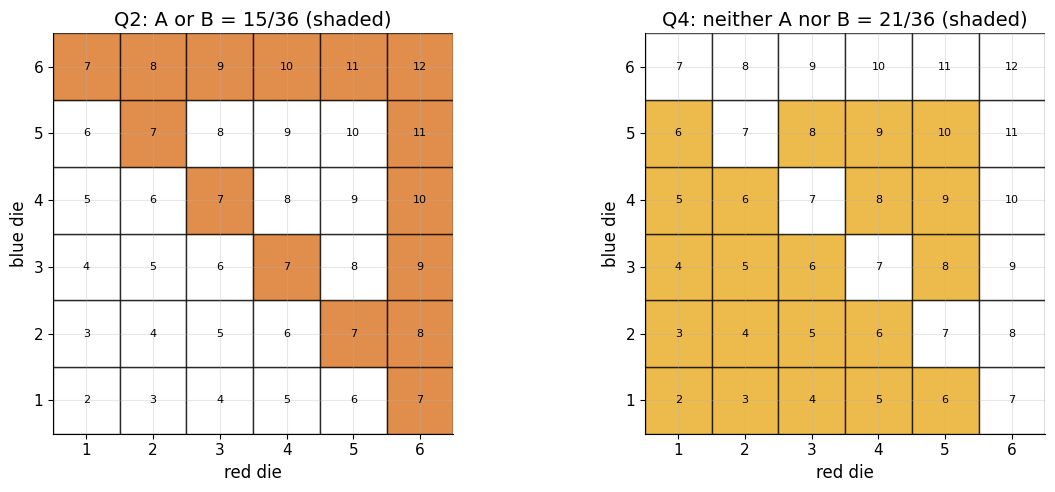

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.2))
for ax, ev, title, col in [(axes[0], A | B, f"Q2: A or B = 15/36 (shaded)", HIGHLIGHT), (axes[1], set(S) - (A | B), "Q4: neither A nor B = 21/36 (shaded)", SIM)]:
    for r, b in S:
        ax.add_patch(Rectangle((r - 0.5, b - 0.5), 1, 1, facecolor=col if (r, b) in ev else "white", edgecolor="black", alpha=0.7))
        ax.text(r, b, f"{r + b}", ha="center", va="center", fontsize=8)
    ax.set_xlim(0.5, 6.5); ax.set_ylim(0.5, 6.5); ax.set_aspect("equal"); ax.set_title(title); ax.set_xlabel("red die"); ax.set_ylabel("blue die")
plt.show()

### 11.5 Interpretation and decision (Example 1)
- **How often is each thing?** A safe move (sum 7) happens in 1 roll out of 6; a bonus (a six on either die) in about 31 % of rolls (11 out of 36); and a roll that is both in only 5.6 % (2 out of 36).
- **Do not just add.** Adding the two chances gives 17/36, but the two outcomes (1, 6) and (6, 1) belong to both events and were counted twice. The correct "safe **or** bonus" chance is **15/36 = 41.7 %**, and the chance of getting neither is **21/36 = 58.3 %**.
- **Doubles** (an extra turn) happen 1 time in 6, so **5 rolls out of 6 give no extra turn**.
- **Simulation:** 200,000 simulated rolls agree with every exact value to within 0.001 (for instance A or B: 0.4161 against 0.4167).
- **Decision.** A player who needs a safe move or a bonus should expect it a little more than 4 times out of 10; for planning a game, count the outcomes, subtract the overlap, and check the result with a quick simulation.

---
### Example 2: a deck of cards (heart or face card)

**Scenario.** Draw one card from a standard 52-card deck. Let $H$ = "heart" (13 cards) and $F$ = "face card: jack, queen or king" (12 cards). What is $P(H\cup F)$? And the probability of "neither"?

### 11.6 By hand, in code and by simulation
**By hand.** Three cards are both a heart and a face card (J, Q, K of hearts), so $P(H\cup F)=\frac{13}{52}+\frac{12}{52}-\frac3{52}=\frac{22}{52}=\frac{11}{26}=0.423$. Neither: $1-\frac{22}{52}=\frac{30}{52}=0.577$.

|H| = 13, |F| = 12, |H and F| = 3; P(H or F) = 0.4231; simulated 0.4248; P(neither) = 0.5769


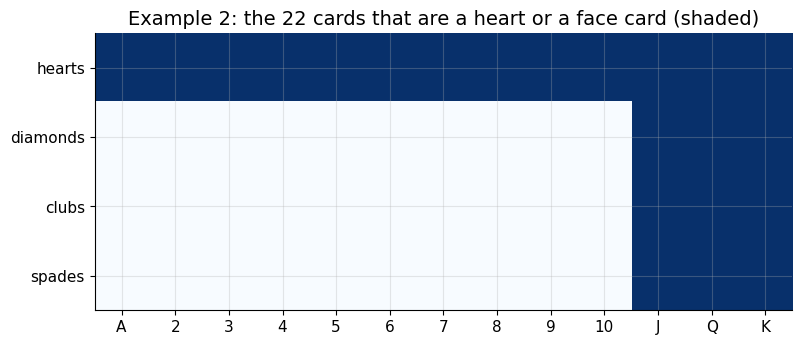

In [13]:
suits = ["hearts", "diamonds", "clubs", "spades"]; ranks = ["A", "2", "3", "4", "5", "6", "7", "8", "9", "10", "J", "Q", "K"]
deck = [(rk, st) for st in suits for rk in ranks]
H = {c for c in deck if c[1] == "hearts"}; F = {c for c in deck if c[0] in ("J", "Q", "K")}
exact_hf = len(H | F) / 52
draws = np.random.default_rng(3).integers(0, 52, 300_000)
sim_hf = np.mean([(deck[i] in H) or (deck[i] in F) for i in draws[:60_000]])
print(f"|H| = {len(H)}, |F| = {len(F)}, |H and F| = {len(H & F)}; P(H or F) = {exact_hf:.4f}; simulated {sim_hf:.4f}; P(neither) = {1 - exact_hf:.4f}")
assert len(H & F) == 3 and np.isclose(exact_hf, 22 / 52) and abs(sim_hf - exact_hf) < 0.01
fig, ax = plt.subplots(figsize=(9, 3.6))
grid = np.array([[1 if (rk, st) in (H | F) else 0 for rk in ranks] for st in suits])
ax.imshow(grid, cmap="Blues", aspect="auto"); ax.set_xticks(range(13)); ax.set_xticklabels(ranks); ax.set_yticks(range(4)); ax.set_yticklabels(suits)
ax.set_title("Example 2: the 22 cards that are a heart or a face card (shaded)")
plt.show()

### 11.6b Interpretation and decision (Example 2)
- The cards that are **both** a heart and a face card (J, Q, K of hearts) would be counted twice by 13 + 12, so the correct count is 13 + 12 - 3 = **22** cards, a probability of **42.3 %**; simulation gives 42.5 %.
- Equivalently, **30 cards** (57.7 %) are neither a heart nor a face card. The same "add, then subtract the overlap" rule works for any two overlapping groups.
- **Decision.** In a card game where hearts and face cards both pay out, about 2 draws in 5 pay; a quick table of the 52 cards (the shaded grid) is the safest way to check.

---
### Example 3: app and website customers (counting with sets)

**Scenario.** A shop has **1,000** customers. **600** use the mobile app, **450** use the website, and **250** use both. A customer is chosen at random. What is the probability that the customer uses the app **or** the website? Neither? Only the website?

### 11.7 By hand, in code and by simulation
**By hand.** $|{\rm app}\cup{\rm web}|=600+450-250=800$ (the 250 who use both were counted twice), so $P(\text{app or web})=0.80$, $P(\text{neither})=0.20$, and "only website" $=450-250=200$ customers, i.e. $0.20$.

app or web: 0.80 | neither: 0.20 | only web: 0.20 | only app: 0.35
simulated: app or web 0.7994, neither 0.2006, only web 0.1998


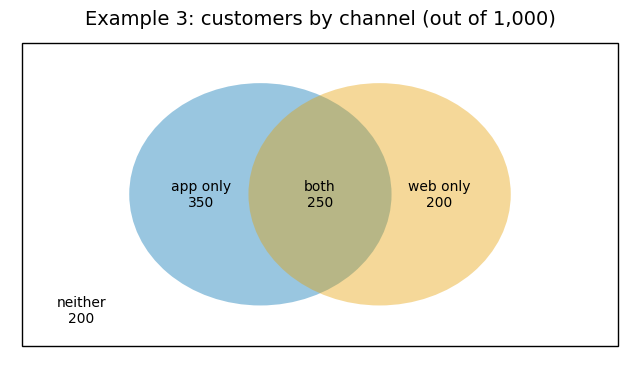

In [14]:
n_cust, n_app, n_web, n_both = 1000, 600, 450, 250
either = n_app + n_web - n_both
print(f"app or web: {either / n_cust:.2f} | neither: {1 - either / n_cust:.2f} | only web: {(n_web - n_both) / n_cust:.2f} | only app: {(n_app - n_both) / n_cust:.2f}")
assert either == 800 and n_web - n_both == 200
# build a concrete customer table and check the counts, then draw random customers
ids = np.arange(n_cust)
uses_app = np.isin(ids, np.arange(0, 600)); uses_web = np.isin(ids, np.arange(350, 800))        # overlap = ids 350..599 = 250 customers
assert uses_app.sum() == 600 and uses_web.sum() == 450 and (uses_app & uses_web).sum() == 250
pick = np.random.default_rng(5).integers(0, n_cust, 200_000)
print(f"simulated: app or web {(uses_app | uses_web)[pick].mean():.4f}, neither {(~(uses_app | uses_web))[pick].mean():.4f}, only web {(uses_web & ~uses_app)[pick].mean():.4f}")
assert abs((uses_app | uses_web)[pick].mean() - 0.8) < 0.005
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.add_patch(Rectangle((0, 0), 10, 6, fill=False, edgecolor="black")); ax.add_patch(Circle((4, 3), 2.2, facecolor=MAIN, alpha=0.4)); ax.add_patch(Circle((6, 3), 2.2, facecolor=SIM, alpha=0.4))
ax.text(3.0, 3, f"app only\n{n_app - n_both}", ha="center", va="center"); ax.text(7.0, 3, f"web only\n{n_web - n_both}", ha="center", va="center"); ax.text(5.0, 3, f"both\n{n_both}", ha="center", va="center")
ax.text(1.0, 0.7, f"neither\n{n_cust - either}", ha="center", va="center"); ax.set_xlim(-0.2, 10.2); ax.set_ylim(-0.2, 6.2); ax.axis("off"); ax.set_title("Example 3: customers by channel (out of 1,000)")
plt.show()

### 11.7b Interpretation and decision (Example 3)
- 600 + 450 = 1,050 is more than the 1,000 customers, a sign that the 250 customers who use both channels were counted twice. The correct number of customers using **at least one** channel is **800 (80 %)**, and **200 (20 %)** use neither.
- Only-app customers are 350 (35 %), only-website customers 200 (20 %) and both 250 (25 %); the four groups add to 1,000.
- A simulation that picks random customers reproduces these shares (79.9 % either, 20.1 % neither).
- **Decision.** The 20 % who use neither channel are the group to reach with other marketing, and the 25 % using both are the loyal core; always draw the overlap before reading a segment report.

## 12. Where it is used

### Statistics
- Every probability model starts with a **sample space** and **events**: hypotheses, p-values ("a result at least this extreme") and confidence statements are all probabilities of events.
- **Sampling** (Module 05) draws a subset of a population, and "the sample contains a defective item" is an event.

### Data science
- **Filtering and segmenting** data is set algebra: customers who use the app **and** the website, users who churned **or** downgraded, rows that are **not** in a segment (`&`, `|`, `~` in pandas).
- **Funnel and overlap analysis** (Example 3): counting overlaps correctly is the inclusion-exclusion rule.

### ML and AI
- **Classification outcomes** are events: "predicted spam and actually spam" (true positive) is an intersection; the confusion matrix is a partition of the sample space.
- **Train/test splits, masks and filters** on data are sets of rows; probabilities of events become the **accuracy, precision and recall** of a model (0a_05 and Module 00).

## 13. Common pitfalls and misconceptions

- **"Equally likely" must be checked.** The sum of two dice is *not* equally likely across 2 to 12 (7 is six times as likely as 2); the 36 *pairs* are. Counting 11 sums as equally likely gives wrong answers.
- **Mutually exclusive does not mean independent**, and it is almost the opposite: if $A$ occurs, $B$ cannot.
- **Double counting overlaps:** $P(A\cup B)$ is not $P(A)+P(B)$ unless the events are mutually exclusive.
- **"Or" in maths is inclusive:** $A\cup B$ includes the case where both happen.
- **Order and labels matter when listing outcomes:** $(1,6)$ and $(6,1)$ are different outcomes of (red, blue).
- **Percent versus probability:** 0.20 and 20 % are the same thing; a probability above 1 is always an error.

## 14. Exercises

1. A fair die is rolled once. Let $E$ be "even" and $G$ be "greater than 3". List $E\cup G$, $E\cap G$, $E^c$ and compute their probabilities.
2. Two coins are tossed. List the sample space. What is the probability of "at least one head"? Solve it with the complement rule.
3. In a class of 40 students, 25 study French, 18 study Spanish and 9 study both. How many study neither? What is the probability that a random student studies exactly one language?
4. Two dice are rolled. What is the probability that the sum is **greater than 9**? That the two dice **differ**? That the sum is **even**?
5. Show with a Venn diagram (or a small numerical example) that $P(A\cup B)\le P(A)+P(B)$ and explain when equality holds.
6. (Harder) Three coins are tossed. Let $A$ = "at least two heads" and $B$ = "the first coin is a head". Compute $P(A)$, $P(B)$, $P(A\cap B)$ and $P(A\cup B)$ by listing all 8 outcomes, and check the addition rule.

Solutions are at the end.

## 15. Summary table

| Idea | Notation | Rule |
|---|---|---|
| Sample space | $S$ | all outcomes, $P(S)=1$ |
| Event | $A\subseteq S$ | a set of outcomes |
| Complement | $A^c$ | $P(A^c)=1-P(A)$ |
| Union | $A\cup B$ | $P(A)+P(B)-P(A\cap B)$ |
| Intersection | $A\cap B$ | outcomes in both |
| Mutually exclusive | $A\cap B=\varnothing$ | $P(A\cup B)=P(A)+P(B)$ |
| Equally likely outcomes | $\lvert A\rvert/N$ | count, then divide |
| De Morgan | $(A\cup B)^c=A^c\cap B^c$ | flip and/or when complementing |

## Solutions

In [15]:
die = {1, 2, 3, 4, 5, 6}; E, G = {2, 4, 6}, {4, 5, 6}
print("1: E or G =", E | G, f"({len(E | G)}/6) | E and G =", E & G, f"({len(E & G)}/6) | E^c =", die - E, f"({len(die - E)}/6)")
coins = list(itertools.product("HT", repeat=2))
print("2: sample space", coins, "| P(at least one head) = 1 - P(TT) =", 1 - 1 / 4)
both, fr, sp = 9, 25, 18
print("3: either =", fr + sp - both, "-> neither =", 40 - (fr + sp - both), "| exactly one:", (fr - both) + (sp - both), "->", ((fr - both) + (sp - both)) / 40)
big = sum(1 for r, b in S if r + b > 9); differ = sum(1 for r, b in S if r != b); even = sum(1 for r, b in S if (r + b) % 2 == 0)
print(f"4: sum > 9: {big}/36 = {big / 36:.4f} | differ: {differ}/36 = {differ / 36:.4f} | even sum: {even}/36 = {even / 36:.4f}")
three = list(itertools.product("HT", repeat=3))
A3 = {o for o in three if o.count("H") >= 2}; B3 = {o for o in three if o[0] == "H"}
print(f"6: P(A) = {len(A3)}/8, P(B) = {len(B3)}/8, P(A and B) = {len(A3 & B3)}/8, P(A or B) = {len(A3 | B3)}/8 ; check {len(A3) / 8 + len(B3) / 8 - len(A3 & B3) / 8}")

1: E or G = {2, 4, 5, 6} (4/6) | E and G = {4, 6} (2/6) | E^c = {1, 3, 5} (3/6)
2: sample space [('H', 'H'), ('H', 'T'), ('T', 'H'), ('T', 'T')] | P(at least one head) = 1 - P(TT) = 0.75
3: either = 34 -> neither = 6 | exactly one: 25 -> 0.625
4: sum > 9: 6/36 = 0.1667 | differ: 30/36 = 0.8333 | even sum: 18/36 = 0.5000
6: P(A) = 4/8, P(B) = 4/8, P(A and B) = 3/8, P(A or B) = 5/8 ; check 0.625


**1.** $E\cup G=\{2,4,5,6\}$, probability $4/6$; $E\cap G=\{4,6\}$, probability $2/6$; $E^c=\{1,3,5\}$, probability $3/6$. Check: $P(E\cup G)=3/6+3/6-2/6=4/6$.

**2.** $S=\{HH,HT,TH,TT\}$. "No heads" is $\{TT\}$ with probability $1/4$, so $P(\text{at least one head})=1-1/4=\mathbf{3/4}$.

**3.** Studying French or Spanish: $25+18-9=34$, so **6 students study neither**. Exactly one language: $(25-9)+(18-9)=25$, probability $25/40=\mathbf{0.625}$.

**4.** Sum greater than 9 means 10, 11 or 12: $3+2+1=6$ outcomes, $6/36=\mathbf{1/6}$. The dice differ in $36-6=30$ outcomes: $\mathbf{5/6}$. An even sum occurs in $18$ of the 36 outcomes: $\mathbf{1/2}$.

**5.** $P(A\cup B)=P(A)+P(B)-P(A\cap B)$ and $P(A\cap B)\ge0$, so $P(A\cup B)\le P(A)+P(B)$. Equality holds exactly when $P(A\cap B)=0$, i.e. when the events are mutually exclusive (for example sum 7 and sum 11 on two dice: $6/36+2/36=8/36$).

**6.** The 8 outcomes are HHH, HHT, HTH, HTT, THH, THT, TTH, TTT. $A$ (at least two heads) has 4 outcomes: $P(A)=4/8$. $B$ (first is H) has 4: $P(B)=4/8$. $A\cap B=\{HHH,HHT,HTH\}$: $3/8$. $A\cup B$ has 5 outcomes: $5/8$, and the addition rule gives $4/8+4/8-3/8=5/8$. ✓